# IBM HR Attrition — Attrition Analysis

This notebook examines employee attrition across demographic, organizational, financial, satisfaction, and tenure-related factors.

The analysis uses the cleaned dataset created in the data-preparation notebook.

## 1. Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Loading the Processed Dataset

In [2]:
df = pd.read_csv("../data/processed/cleaned_hr_data.csv")

In [3]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,AgeGroup,TenureGroup,YearsInCurrentRoleGroup,IncomeGroup
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,0,1,6,4,0,5,36–45,Established (6–10),3–5 years,5000–7999
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,3,3,10,7,1,7,46–55,Established (6–10),6–10 years,5000–7999
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,3,3,0,0,0,0,36–45,New Employees (0–2),0–2 years,Under 3000
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,3,3,8,7,3,0,26–35,Established (6–10),6–10 years,Under 3000
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,3,3,2,2,2,2,26–35,New Employees (0–2),0–2 years,3000–4999


In [4]:
df.shape

(1470, 36)

In [5]:
df["Attrition"].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

## 3. Overall Attrition Rate

In [6]:
attrition_counts = df["Attrition"].value_counts()

attrition_counts

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [7]:
attrition_percentages = (
    df["Attrition"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

attrition_percentages

Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64

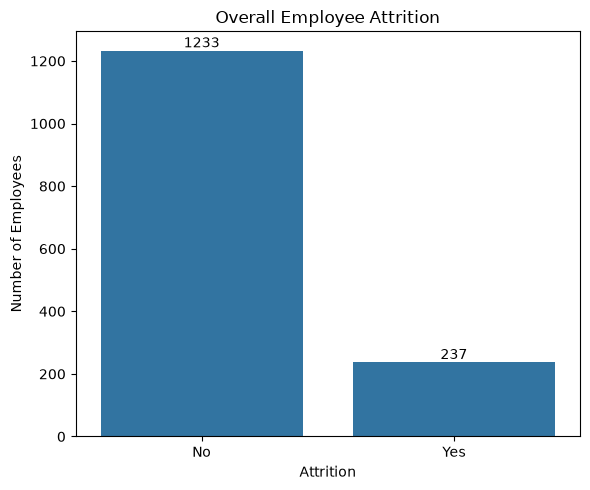

In [8]:
plt.figure(figsize=(6, 5))

ax = sns.barplot(
    x=attrition_counts.index,
    y=attrition_counts.values
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Overall Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

In [10]:
retention_rate = (
    (df["Attrition"].eq("No").mean() * 100)
    .round(2)
)

attrition_rate = (
    (df["Attrition"].eq("Yes").mean() * 100)
    .round(2)
)

print(f"Retention rate: {retention_rate}%")
print(f"Attrition rate: {attrition_rate}%")

Retention rate: 83.88%
Attrition rate: 16.12%


**Observation:** The sampled workforce has a retention rate of 83.88% and an attrition rate of 16.12%. Although most employees remain with the company, the following sections examine how attrition varies across different employee characteristics and working conditions.

## 4. Attrition by Department

In [11]:
attrition_department_counts = pd.crosstab(
    df["Department"],
    df["Attrition"]
)

attrition_department_counts

Attrition,No,Yes
Department,,
Human Resources,51,12
Research & Development,828,133
Sales,354,92


In [12]:
attrition_department_rates = (
    pd.crosstab(
        df["Department"],
        df["Attrition"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

In [13]:
attrition_department_rates = (
    attrition_department_rates
    .sort_values(by="Yes", ascending=False)
)

attrition_department_rates

Attrition,No,Yes
Department,,
Sales,79.37,20.63
Human Resources,80.95,19.05
Research & Development,86.16,13.84


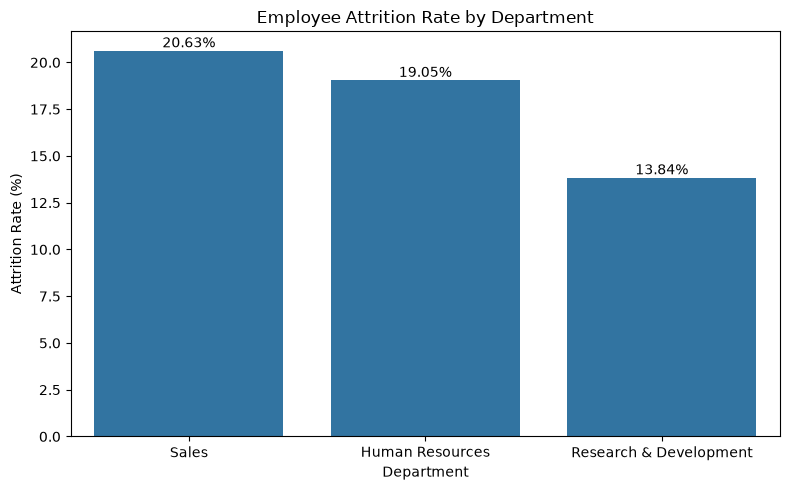

In [14]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=attrition_department_rates.index,
    y=attrition_department_rates["Yes"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.title("Employee Attrition Rate by Department")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

**Observation:** Attrition is present across all three departments. Sales has the highest attrition rate, followed closely by Human Resources, while Research and Development has the lowest rate. However, the differences are not large enough to suggest that department alone explains employee turnover.

## 5. Attrition by Job Role

In [15]:
attrition_job_role_counts = pd.crosstab(
    df["JobRole"],
    df["Attrition"]
)

attrition_job_role_counts

Attrition,No,Yes
JobRole,,
Healthcare Representative,122,9
Human Resources,40,12
Laboratory Technician,197,62
Manager,97,5
Manufacturing Director,135,10
Research Director,78,2
Research Scientist,245,47
Sales Executive,269,57
Sales Representative,50,33


In [16]:
attrition_job_role_rates = (
    pd.crosstab(
        df["JobRole"],
        df["Attrition"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

In [17]:
attrition_job_role_rates = (
    attrition_job_role_rates
    .sort_values(by="Yes", ascending=False)
)

attrition_job_role_rates

Attrition,No,Yes
JobRole,,
Sales Representative,60.24,39.76
Laboratory Technician,76.06,23.94
Human Resources,76.92,23.08
Sales Executive,82.52,17.48
Research Scientist,83.90,16.10
Manufacturing Director,93.10,6.90
Healthcare Representative,93.13,6.87
Manager,95.10,4.90
Research Director,97.50,2.50


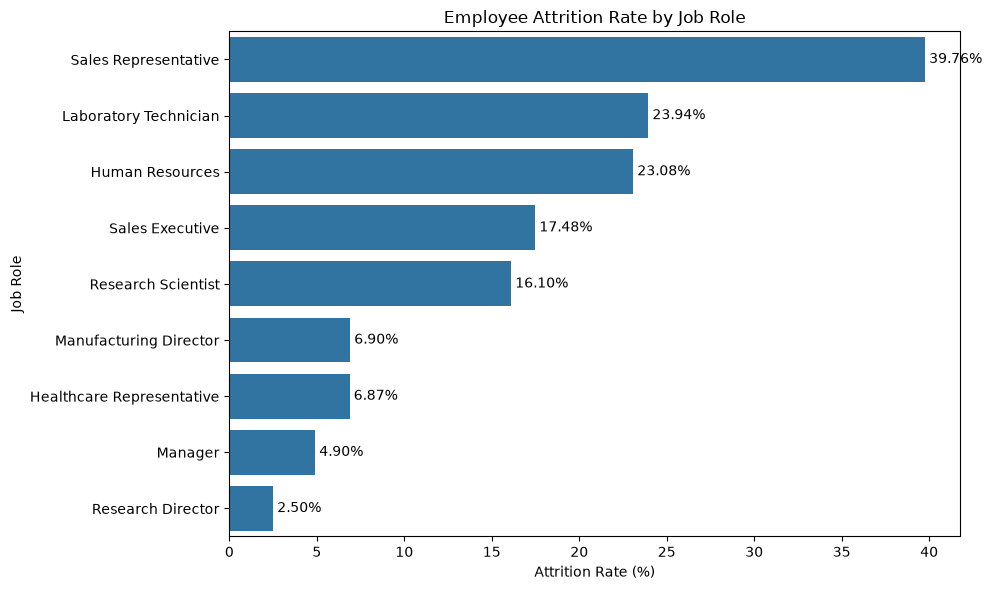

In [18]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=attrition_job_role_rates["Yes"],
    y=attrition_job_role_rates.index
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Employee Attrition Rate by Job Role")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")

plt.tight_layout()
plt.show()

**Observation:** Sales Representatives have the highest attrition rate by a considerable margin. Laboratory Technicians and Human Resources employees also show relatively high turnover, while Research Directors, Managers, and Healthcare Representatives have the lowest attrition rates.

## 6. Attrition by Gender

In [19]:
attrition_gender_counts = pd.crosstab(
    df["Gender"],
    df["Attrition"]
)

attrition_gender_counts

Attrition,No,Yes
Gender,,
Female,501,87
Male,732,150


In [20]:
attrition_gender_rates = (
    pd.crosstab(
        df["Gender"],
        df["Attrition"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

attrition_gender_rates

Attrition,No,Yes
Gender,,
Female,85.20,14.80
Male,82.99,17.01


In [24]:
attrition_gender_table = pd.DataFrame({
    "Gender": attrition_gender_rates.index,
    "Distribution": [
        (
            f"Stayed: {attrition_gender_rates.loc[gender, 'No']:.2f}% / "
            f"Left: {attrition_gender_rates.loc[gender, 'Yes']:.2f}%"
        )
        for gender in attrition_gender_rates.index
    ]
})

attrition_gender_table

,Gender,Distribution
0,Female,Stayed: 85.20% / Left: 14.80%
1,Male,Stayed: 82.99% / Left: 17.01%


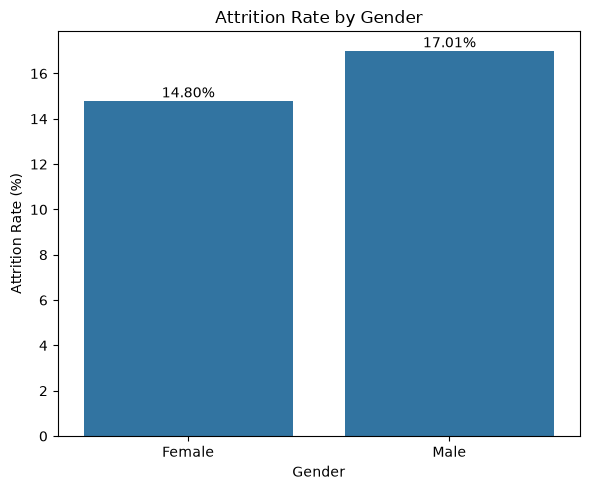

In [25]:
plt.figure(figsize=(6, 5))

ax = sns.barplot(
    x=attrition_gender_rates.index,
    y=attrition_gender_rates["Yes"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.title("Attrition Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

**Observation:** Male and female employees have very similar attrition rates in the sampled workforce. This suggests that gender is not a strong individual indicator of employee turnover in this dataset.

## 7. Attrition by Age Group

In [26]:
age_group_order = [
    "18–25",
    "26–35",
    "36–45",
    "46–55",
    "56–60"
]

In [27]:
attrition_age_counts = pd.crosstab(
    df["AgeGroup"],
    df["Attrition"]
).reindex(age_group_order)

attrition_age_counts

Attrition,No,Yes
AgeGroup,,
18–25,79,44
26–35,490,116
36–45,425,43
46–55,200,26
56–60,39,8


In [28]:
attrition_age_rates = (
    pd.crosstab(
        df["AgeGroup"],
        df["Attrition"],
        normalize="index"
    )
    .reindex(age_group_order)
    .mul(100)
    .round(2)
)

attrition_age_rates

Attrition,No,Yes
AgeGroup,,
18–25,64.23,35.77
26–35,80.86,19.14
36–45,90.81,9.19
46–55,88.50,11.50
56–60,82.98,17.02


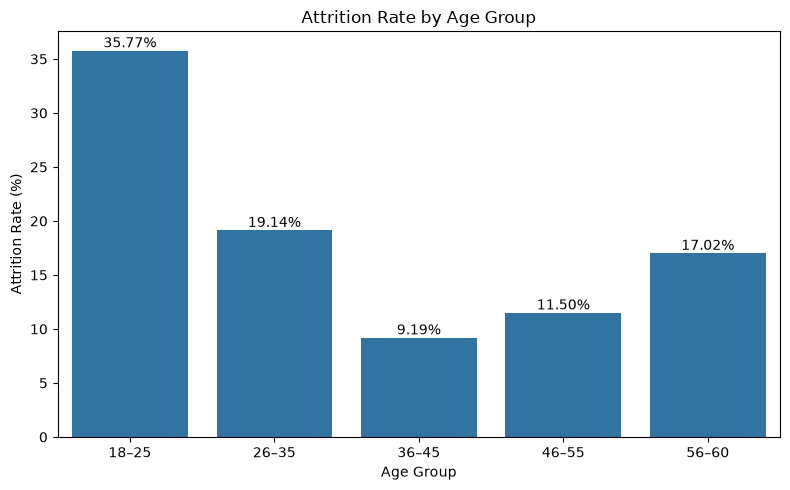

In [29]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=attrition_age_rates.index,
    y=attrition_age_rates["Yes"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.title("Attrition Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

**Observation:** Employees aged 18–25 have the highest attrition rate in the sampled workforce, followed by those aged 26–35. Attrition generally decreases among the older age groups, with employees aged 36–45 showing the lowest turnover rate.

## 8. Attrition by Marital Status

In [30]:
attrition_marital_counts = pd.crosstab(
    df["MaritalStatus"],
    df["Attrition"]
)

attrition_marital_counts

Attrition,No,Yes
MaritalStatus,,
Divorced,294,33
Married,589,84
Single,350,120


In [31]:
attrition_marital_rates = (
    pd.crosstab(
        df["MaritalStatus"],
        df["Attrition"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

In [32]:
attrition_marital_rates = (
    attrition_marital_rates
    .sort_values(by="Yes", ascending=False)
)

attrition_marital_rates

Attrition,No,Yes
MaritalStatus,,
Single,74.47,25.53
Married,87.52,12.48
Divorced,89.91,10.09


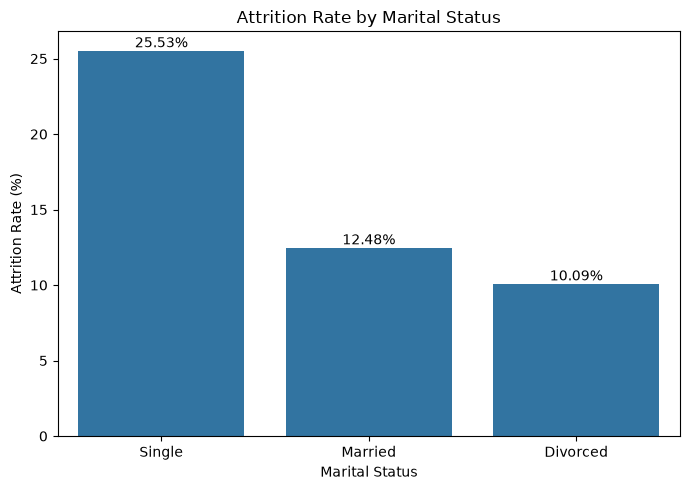

In [33]:
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=attrition_marital_rates.index,
    y=attrition_marital_rates["Yes"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.title("Attrition Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

**Observation:** Single employees have the highest attrition rate in the sampled workforce by a considerable margin. Married and divorced employees have noticeably lower turnover rates, suggesting that marital status may be associated with employee retention.

## 9. Attrition by Education Level

In [34]:
education_labels = {
    1: "Below College",
    2: "College",
    3: "Bachelor",
    4: "Master",
    5: "Doctor"
}

In [35]:
attrition_education_counts = pd.crosstab(
    df["Education"],
    df["Attrition"]
)

attrition_education_counts

Attrition,No,Yes
Education,,
1,139,31
2,238,44
3,473,99
4,340,58
5,43,5


In [36]:
attrition_education_rates = (
    pd.crosstab(
        df["Education"],
        df["Attrition"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

attrition_education_rates

Attrition,No,Yes
Education,,
1,81.76,18.24
2,84.40,15.60
3,82.69,17.31
4,85.43,14.57
5,89.58,10.42


In [37]:
attrition_education_plot = (
    attrition_education_rates
    .reset_index()
)

attrition_education_plot["Education Level"] = (
    attrition_education_plot["Education"]
    .map(education_labels)
)

attrition_education_plot["Level Label"] = (
    attrition_education_plot["Education"].astype(str)
    + " - "
    + attrition_education_plot["Education Level"]
)

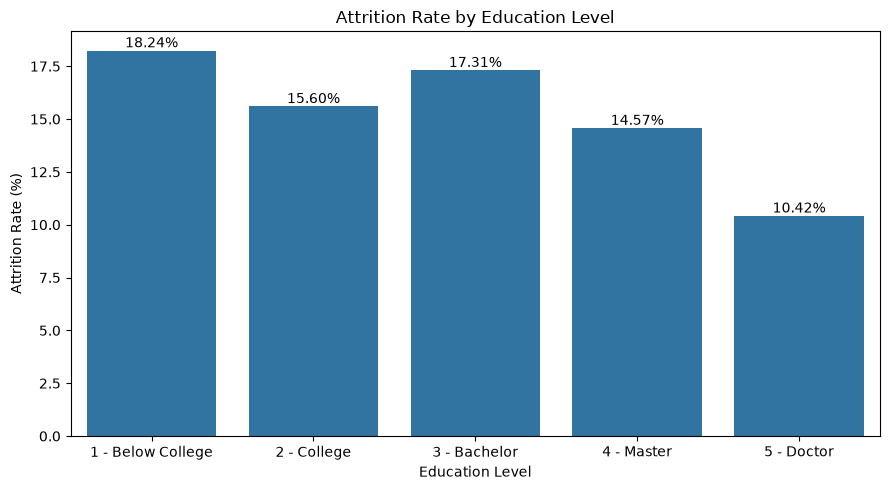

In [38]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=attrition_education_plot,
    x="Level Label",
    y="Yes"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.title("Attrition Rate by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

**Observation:** Employees with doctoral-level education have the lowest attrition rate in the sampled workforce. The remaining education levels have relatively similar turnover rates, so the data does not show a clear and consistent decrease in attrition as education level increases.

## 10. Attrition by Overtime

In [39]:
attrition_overtime_counts = pd.crosstab(
    df["OverTime"],
    df["Attrition"]
)

attrition_overtime_counts

Attrition,No,Yes
OverTime,,
No,944,110
Yes,289,127


In [40]:
attrition_overtime_rates = (
    pd.crosstab(
        df["OverTime"],
        df["Attrition"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

attrition_overtime_rates

Attrition,No,Yes
OverTime,,
No,89.56,10.44
Yes,69.47,30.53


In [41]:
overtime_attrition_difference = (
    attrition_overtime_rates.loc["Yes", "Yes"]
    - attrition_overtime_rates.loc["No", "Yes"]
)

print(
    f"Attrition-rate difference: "
    f"{overtime_attrition_difference:.2f} percentage points"
)

Attrition-rate difference: 20.09 percentage points


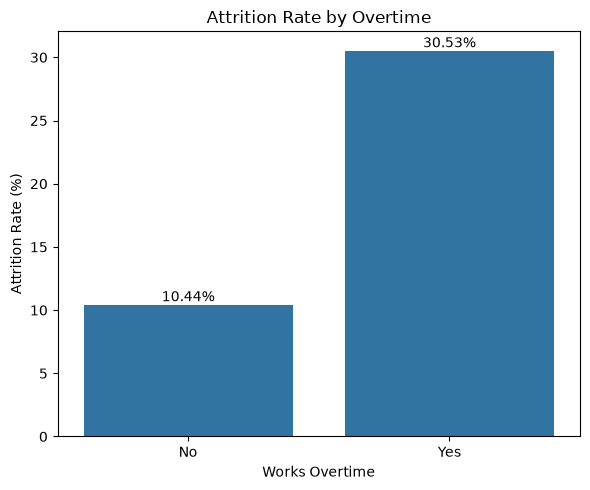

In [42]:
plt.figure(figsize=(6, 5))

ax = sns.barplot(
    x=attrition_overtime_rates.index,
    y=attrition_overtime_rates["Yes"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.title("Attrition Rate by Overtime")
plt.xlabel("Works Overtime")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

**Observation:** Employees who work overtime have a substantially higher attrition rate than those who do not. The difference is approximately 20 percentage points, making overtime one of the strongest individual indicators of employee turnover identified so far.

## 11. Attrition by Business Travel

In [43]:
business_travel_order = [
    "Non-Travel",
    "Travel_Rarely",
    "Travel_Frequently"
]

In [44]:
attrition_travel_counts = (
    pd.crosstab(
        df["BusinessTravel"],
        df["Attrition"]
    )
    .reindex(business_travel_order)
)

attrition_travel_counts

Attrition,No,Yes
BusinessTravel,,
Non-Travel,138,12
Travel_Rarely,887,156
Travel_Frequently,208,69


In [45]:
attrition_travel_rates = (
    pd.crosstab(
        df["BusinessTravel"],
        df["Attrition"],
        normalize="index"
    )
    .reindex(business_travel_order)
    .mul(100)
    .round(2)
)

attrition_travel_rates

Attrition,No,Yes
BusinessTravel,,
Non-Travel,92.00,8.00
Travel_Rarely,85.04,14.96
Travel_Frequently,75.09,24.91


In [46]:
business_travel_labels = [
    "Non-Travel",
    "Travel Rarely",
    "Travel Frequently"
]

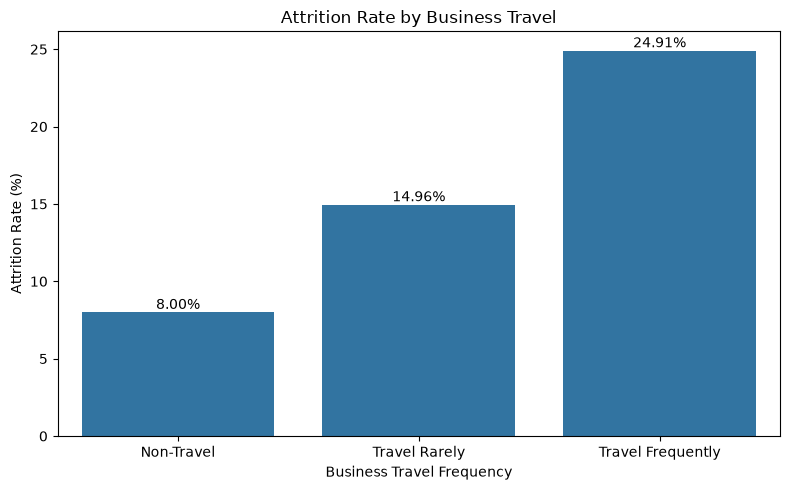

In [47]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=business_travel_labels,
    y=attrition_travel_rates["Yes"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.title("Attrition Rate by Business Travel")
plt.xlabel("Business Travel Frequency")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

**Observation:** Attrition increases with business-travel frequency. Employees who travel frequently have the highest turnover rate, while employees who do not travel have the lowest, suggesting that frequent business travel may contribute to employee departure.

## 12. Attrition by Job Satisfaction

In [48]:
job_satisfaction_labels = {
    1: "Low",
    2: "Medium",
    3: "High",
    4: "Very High"
}

In [49]:
attrition_job_satisfaction_counts = pd.crosstab(
    df["JobSatisfaction"],
    df["Attrition"]
)

attrition_job_satisfaction_counts

Attrition,No,Yes
JobSatisfaction,,
1,223,66
2,234,46
3,369,73
4,407,52


In [50]:
attrition_job_satisfaction_table = pd.DataFrame({
    "Level": attrition_job_satisfaction_counts.index,
    "Job Satisfaction": (
        attrition_job_satisfaction_counts.index
        .map(job_satisfaction_labels)
    ),
    "Stayed": attrition_job_satisfaction_counts["No"].values,
    "Left": attrition_job_satisfaction_counts["Yes"].values
})

attrition_job_satisfaction_table

,Level,Job Satisfaction,Stayed,Left
0,1,Low,223,66
1,2,Medium,234,46
2,3,High,369,73
3,4,Very High,407,52


In [51]:
attrition_job_satisfaction_rates = (
    pd.crosstab(
        df["JobSatisfaction"],
        df["Attrition"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

attrition_job_satisfaction_rates

Attrition,No,Yes
JobSatisfaction,,
1,77.16,22.84
2,83.57,16.43
3,83.48,16.52
4,88.67,11.33


In [52]:
job_satisfaction_names = [
    f"{level} - {job_satisfaction_labels[level]}"
    for level in attrition_job_satisfaction_rates.index
]

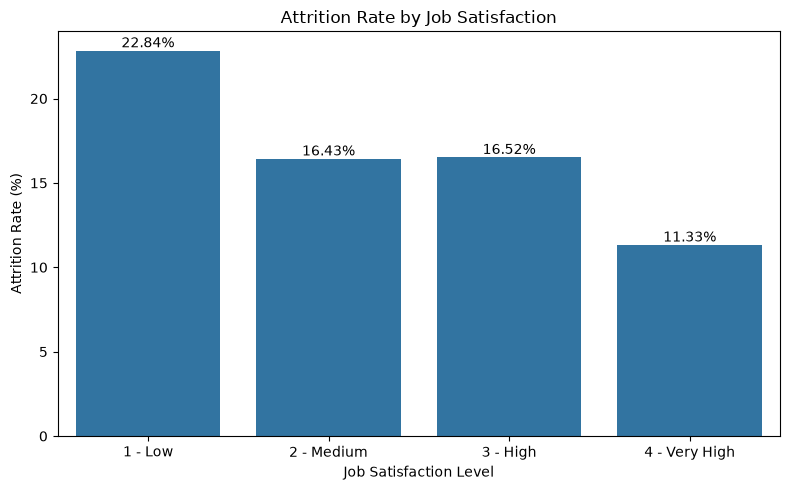

In [53]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=job_satisfaction_names,
    y=attrition_job_satisfaction_rates["Yes"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.title("Attrition Rate by Job Satisfaction")
plt.xlabel("Job Satisfaction Level")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

**Observation:** Employees reporting low job satisfaction have the highest attrition rate, while those reporting very high satisfaction have the lowest. This suggests that job satisfaction is associated with employee retention, although the relationship is not perfectly linear across the middle satisfaction levels.

## 13. Attrition by Work-Life Balance

In [54]:
work_life_balance_labels = {
    1: "Bad",
    2: "Good",
    3: "Better",
    4: "Best"
}

In [55]:
attrition_work_life_balance_counts = pd.crosstab(
    df["WorkLifeBalance"],
    df["Attrition"]
)

attrition_work_life_balance_counts

Attrition,No,Yes
WorkLifeBalance,,
1,55,25
2,286,58
3,766,127
4,126,27


In [56]:
attrition_work_life_balance_table = pd.DataFrame({
    "Level": attrition_work_life_balance_counts.index,
    "Work-Life Balance": (
        attrition_work_life_balance_counts.index
        .map(work_life_balance_labels)
    ),
    "Stayed": attrition_work_life_balance_counts["No"].values,
    "Left": attrition_work_life_balance_counts["Yes"].values
})

attrition_work_life_balance_table

,Level,Work-Life Balance,Stayed,Left
0,1,Bad,55,25
1,2,Good,286,58
2,3,Better,766,127
3,4,Best,126,27


In [57]:
attrition_work_life_balance_rates = (
    pd.crosstab(
        df["WorkLifeBalance"],
        df["Attrition"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

attrition_work_life_balance_rates

Attrition,No,Yes
WorkLifeBalance,,
1,68.75,31.25
2,83.14,16.86
3,85.78,14.22
4,82.35,17.65


In [58]:
attrition_work_life_balance_rates = (
    pd.crosstab(
        df["WorkLifeBalance"],
        df["Attrition"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

attrition_work_life_balance_rates

Attrition,No,Yes
WorkLifeBalance,,
1,68.75,31.25
2,83.14,16.86
3,85.78,14.22
4,82.35,17.65


In [59]:
work_life_balance_names = [
    f"{level} - {work_life_balance_labels[level]}"
    for level in attrition_work_life_balance_rates.index
]

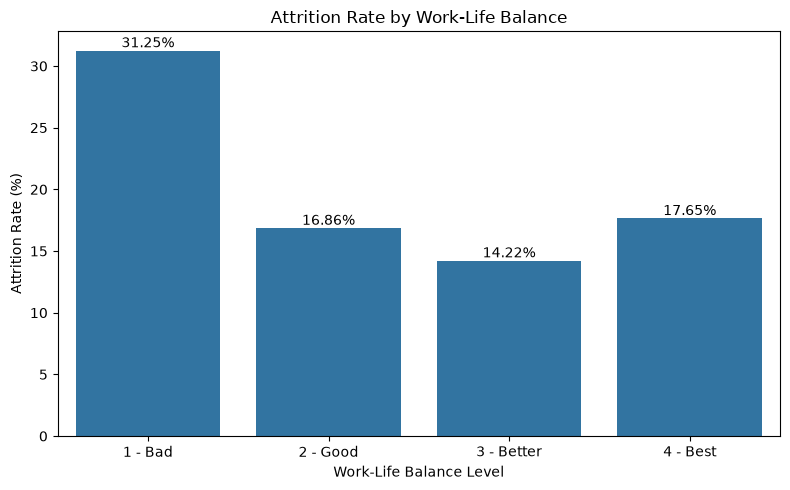

In [60]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=work_life_balance_names,
    y=attrition_work_life_balance_rates["Yes"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.title("Attrition Rate by Work-Life Balance")
plt.xlabel("Work-Life Balance Level")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

**Observation:** Employees reporting the lowest work-life balance have the highest attrition rate in the sampled workforce. The other three levels show noticeably lower turnover, suggesting that particularly poor work-life balance may be associated with a greater likelihood of employee departure.

## 14. Attrition by Monthly Income

In [61]:
monthly_income_by_attrition = (
    df.groupby("Attrition")["MonthlyIncome"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

monthly_income_by_attrition

,count,mean,median,min,max
Attrition,,,,,
No,1233,6832.74,5204.0,1051,19999
Yes,237,4787.09,3202.0,1009,19859


In [62]:
income_group_order = [
    "Under 3000",
    "3000–4999",
    "5000–7999",
    "8000–11999",
    "12000–15999",
    "16000+"
]

In [63]:
attrition_income_counts = (
    pd.crosstab(
        df["IncomeGroup"],
        df["Attrition"]
    )
    .reindex(income_group_order)
)

attrition_income_counts

Attrition,No,Yes
IncomeGroup,,
Under 3000,282,113
3000–4999,304,50
5000–7999,306,34
8000–11999,157,29
12000–15999,63,6
16000+,121,5


In [64]:
attrition_income_rates = (
    pd.crosstab(
        df["IncomeGroup"],
        df["Attrition"],
        normalize="index"
    )
    .reindex(income_group_order)
    .mul(100)
    .round(2)
)

attrition_income_rates

Attrition,No,Yes
IncomeGroup,,
Under 3000,71.39,28.61
3000–4999,85.88,14.12
5000–7999,90.00,10.00
8000–11999,84.41,15.59
12000–15999,91.30,8.70
16000+,96.03,3.97


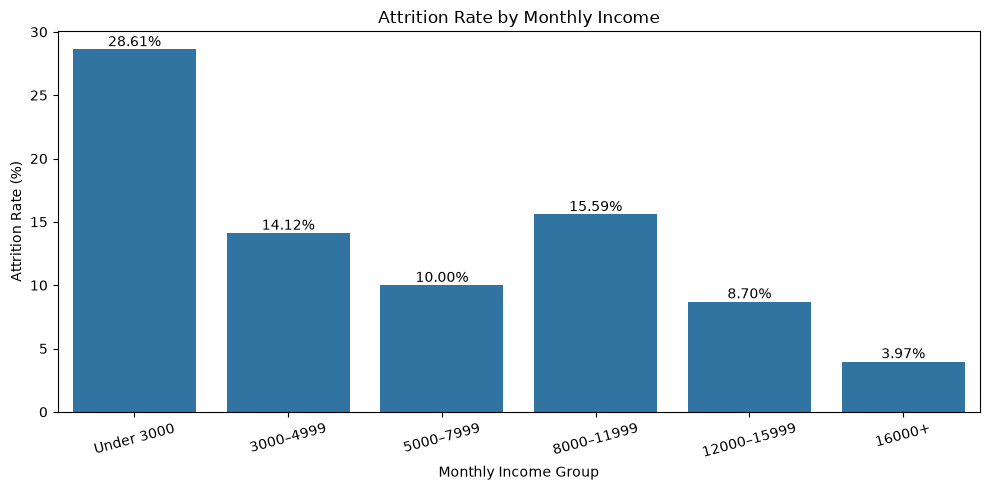

In [65]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=attrition_income_rates.index,
    y=attrition_income_rates["Yes"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.title("Attrition Rate by Monthly Income")
plt.xlabel("Monthly Income Group")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

**Observation:** Employees earning under 3,000 per month have the highest attrition rate at 28.61%. Attrition generally decreases across the higher income groups, although the 8,000–11,999 group shows a temporary increase. Employees earning 16,000 or more have the lowest turnover rate.

## 15. Attrition by Years at Company

In [66]:
years_at_company_by_attrition = (
    df.groupby("Attrition")["YearsAtCompany"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

years_at_company_by_attrition

,count,mean,median,min,max
Attrition,,,,,
No,1233,7.37,6.0,0,37
Yes,237,5.13,3.0,0,40


In [67]:
tenure_group_order = [
    "New Employees (0–2)",
    "Early Career (3–5)",
    "Established (6–10)",
    "Experienced (11–20)",
    "Long Tenure (21+)"
]

In [68]:
attrition_tenure_counts = (
    pd.crosstab(
        df["TenureGroup"],
        df["Attrition"]
    )
    .reindex(tenure_group_order)
)

attrition_tenure_counts

Attrition,No,Yes
TenureGroup,,
New Employees (0–2),240,102
Early Career (3–5),374,60
Established (6–10),393,55
Experienced (11–20),168,12
Long Tenure (21+),58,8


In [69]:
attrition_tenure_rates = (
    pd.crosstab(
        df["TenureGroup"],
        df["Attrition"],
        normalize="index"
    )
    .reindex(tenure_group_order)
    .mul(100)
    .round(2)
)

attrition_tenure_rates

Attrition,No,Yes
TenureGroup,,
New Employees (0–2),70.18,29.82
Early Career (3–5),86.18,13.82
Established (6–10),87.72,12.28
Experienced (11–20),93.33,6.67
Long Tenure (21+),87.88,12.12


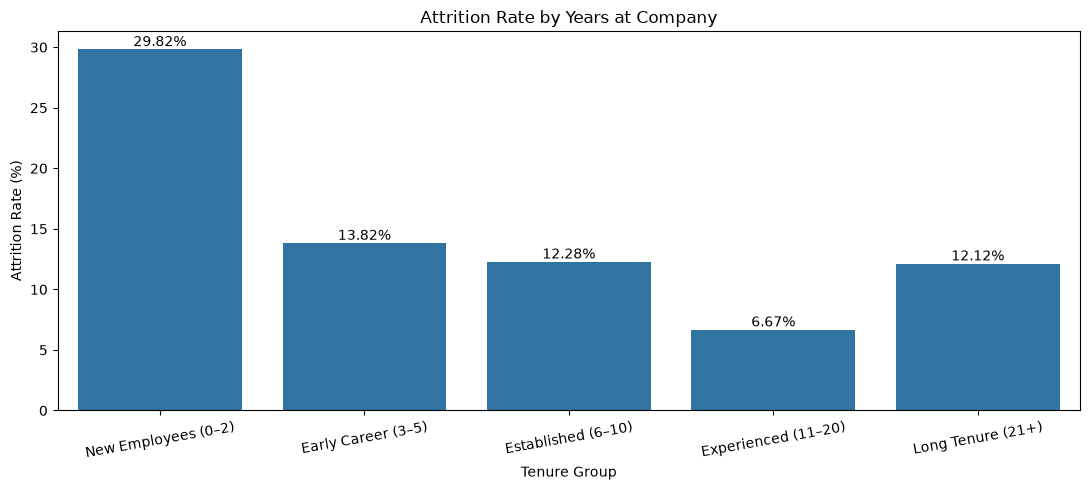

In [70]:
plt.figure(figsize=(11, 5))

ax = sns.barplot(
    x=attrition_tenure_rates.index,
    y=attrition_tenure_rates["Yes"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.title("Attrition Rate by Years at Company")
plt.xlabel("Tenure Group")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=10)

plt.tight_layout()
plt.show()

**Observation:** New employees with 0–2 years at the company have the highest attrition rate at 29.82%. Turnover falls considerably after the first two years and reaches its lowest level among employees with 11–20 years of tenure. This suggests that the earliest stage of employment is a particularly important period for retention.

## 16. Attrition by Years in Current Role

In [71]:
years_in_current_role_by_attrition = (
    df.groupby("Attrition")["YearsInCurrentRole"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

years_in_current_role_by_attrition

,count,mean,median,min,max
Attrition,,,,,
No,1233,4.48,3.0,0,18
Yes,237,2.90,2.0,0,15


In [72]:
years_in_role_group_order = [
    "0–2 years",
    "3–5 years",
    "6–10 years",
    "11+ years"
]

In [73]:
attrition_current_role_counts = (
    pd.crosstab(
        df["YearsInCurrentRoleGroup"],
        df["Attrition"]
    )
    .reindex(years_in_role_group_order)
)

attrition_current_role_counts

Attrition,No,Yes
YearsInCurrentRoleGroup,,
0–2 years,521,152
3–5 years,243,32
6–10 years,396,48
11+ years,73,5


In [74]:
attrition_current_role_rates = (
    pd.crosstab(
        df["YearsInCurrentRoleGroup"],
        df["Attrition"],
        normalize="index"
    )
    .reindex(years_in_role_group_order)
    .mul(100)
    .round(2)
)

attrition_current_role_rates

Attrition,No,Yes
YearsInCurrentRoleGroup,,
0–2 years,77.41,22.59
3–5 years,88.36,11.64
6–10 years,89.19,10.81
11+ years,93.59,6.41


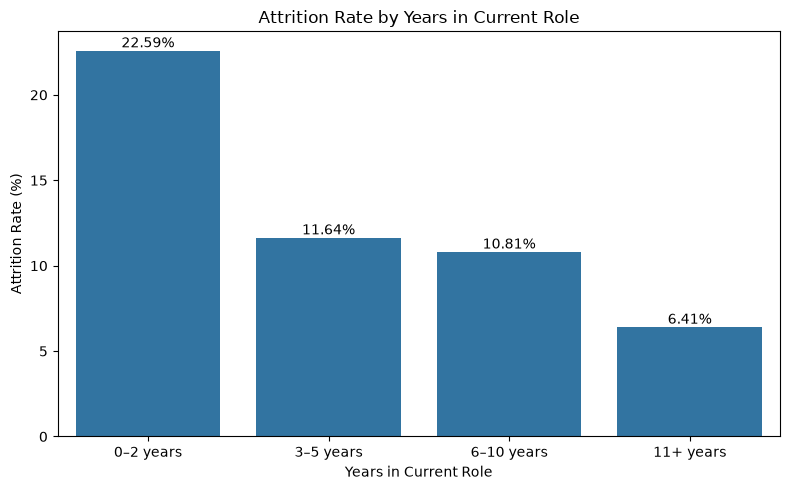

In [75]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=attrition_current_role_rates.index,
    y=attrition_current_role_rates["Yes"]
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.title("Attrition Rate by Years in Current Role")
plt.xlabel("Years in Current Role")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()

**Observation:** Employees who have spent 0–2 years in their current role have the highest attrition rate at 22.59%. Attrition decreases steadily as time in the role increases, reaching its lowest level among employees who have remained in the same role for more than 10 years.